In [2]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)

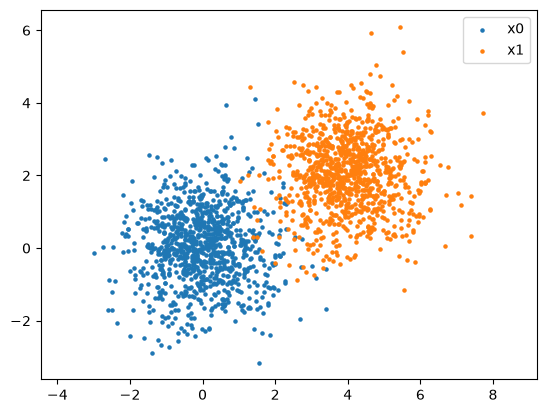

In [3]:
n = 1000

x0 = torch.randn(n, 2)

x1 = x0 + torch.tensor([4.0, 2.0])

plt.scatter(x0[:, 0], x0[:, 1], s=5, label="x0")
plt.scatter(x1[:, 0], x1[:, 1], s=5, label="x1")

plt.axis("equal")
plt.legend()
plt.show()

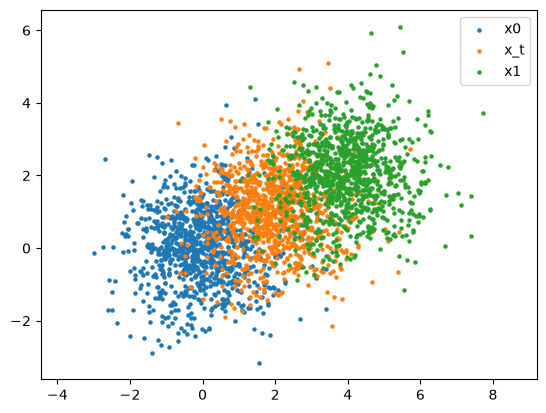

In [4]:
t = 0.5

xt = (1 - t) * x0 + t * x1

plt.scatter(x0[:, 0], x0[:, 1], s=5, label="x0")
plt.scatter(xt[:, 0], xt[:, 1], s=5, label="x_t")
plt.scatter(x1[:, 0], x1[:, 1], s=5, label="x1")

plt.axis("equal")
plt.legend()
plt.show()

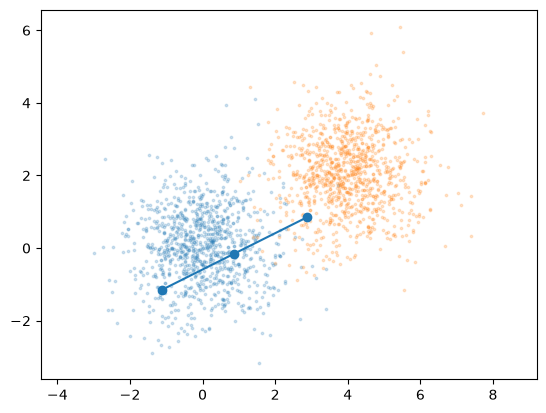

In [5]:
i = 0

plt.scatter(x0[:, 0], x0[:, 1], s=3, alpha=0.2)
plt.scatter(x1[:, 0], x1[:, 1], s=3, alpha=0.2)

plt.plot(
    [x0[i, 0], xt[i, 0], x1[i, 0]],
    [x0[i, 1], xt[i, 1], x1[i, 1]],
    marker="o",
)

plt.axis("equal")
plt.show()

In [6]:
from torch import nn


class FlowMap(nn.Module):
    def __init__(self, dim=2, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim + 2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, x, s, t):
        st = torch.cat([s, t], dim=-1)
        inp = torch.cat([x, st], dim=-1)

        return self.net(inp)

In [7]:
batch_size = 256

x0_batch = torch.randn(batch_size, 2)
x1_batch = x0_batch + torch.tensor([4.0, 2.0])

s = torch.rand(batch_size, 1)
t = s + (1 - s) * torch.rand(batch_size, 1)

xs = (1 - s) * x0_batch + s * x1_batch
xt = (1 - t) * x0_batch + t * x1_batch

print(s[:5].squeeze())
print(t[:5].squeeze())

tensor([0.8900, 0.6358, 0.0849, 0.3495, 0.5992])
tensor([0.9574, 0.8127, 0.3158, 0.7960, 0.7032])


In [8]:
model = FlowMap()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []

for step in range(2000):
    batch_size = 256

    x0_batch = torch.randn(batch_size, 2)
    x1_batch = x0_batch + torch.tensor([4.0, 2.0])

    s = torch.rand(batch_size, 1)
    t = s + (1 - s) * torch.rand(batch_size, 1)

    xs = (1 - s) * x0_batch + s * x1_batch
    xt = (1 - t) * x0_batch + t * x1_batch

    pred = model(xs, s, t)

    loss = (pred - xt).pow(2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 200 == 0:
        print(f"step {step:4d} | loss {loss.item():.6f}")

step    0 | loss 7.715077
step  200 | loss 0.149427
step  400 | loss 0.001874
step  600 | loss 0.000580
step  800 | loss 0.000226
step 1000 | loss 0.000206
step 1200 | loss 0.000164
step 1400 | loss 0.000116
step 1600 | loss 0.000096
step 1800 | loss 0.000078


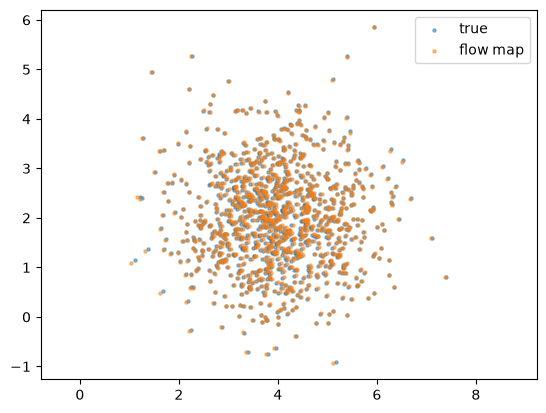

In [9]:
x0_test = torch.randn(1000, 2)

s = torch.zeros(1000, 1)
t = torch.ones(1000, 1)

with torch.no_grad():
    x1_pred = model(x0_test, s, t)

x1_true = x0_test + torch.tensor([4.0, 2.0])

plt.scatter(
    x1_true[:, 0],
    x1_true[:, 1],
    s=5,
    alpha=0.5,
    label="true",
)

plt.scatter(
    x1_pred[:, 0],
    x1_pred[:, 1],
    s=5,
    alpha=0.5,
    label="flow map",
)

plt.axis("equal")
plt.legend()
plt.show()

In [10]:
x0_test = torch.randn(1000, 2)

zero = torch.zeros(1000, 1)
half = torch.full((1000, 1), 0.5)
one = torch.ones(1000, 1)

with torch.no_grad():
    # 한 번에 0 → 1
    x_direct = model(x0_test, zero, one)

    # 두 번에 0 → 0.5 → 1
    x_half = model(x0_test, zero, half)
    x_composed = model(x_half, half, one)

error = (x_direct - x_composed).pow(2).mean()

print("composition error:", error.item())

composition error: 0.0010036678286269307
